# PRÉDIRE LES ANNULATIONS DE RÉSERVATIONS HÔTELIÈRES

# 1. Python / Exploration et préparation

## 1 Importation et chargement

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Chargement du fichier brut (exploration) et du fichier nettoyé par Zohair (analyses, SQL et modèles)
df_raw = pd.read_csv("../data/hotel_bookings.csv")
df = pd.read_csv("../data/hotel_bookings_clean.csv")

In [2]:
df_raw.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 2 Structure et valeurs manquantes

In [3]:
print(df_raw.shape)
print(df_raw.isnull().sum()[df_raw.isnull().sum() > 0])
print(df.shape, df.isnull().sum().sum())
df_raw.info()

(119390, 32)
children         4
country        488
agent        16340
company     112593
dtype: int64
(87208, 31) 0


<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

- Fichier brut : 119 390 lignes et 32 colonnes. Valeurs manquantes dans children (4), country (488), agent (16 340) et company (112 593).
- Fichier nettoyé (notebook 01 de Zohair) : 87 208 lignes, 31 colonnes, plus aucune valeur manquante. C'est ce fichier qui sert pour le SQL et les modèles.

## 3. Statistiques descriptives

In [4]:
df_raw.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


- Fichier brut : la moyenne de is_canceled est 0,370416, soit environ 37 % d'annulations avant nettoyage.
- adr (prix moyen par nuit) va de -6,38 à 5 400 et adults monte jusqu'à 55 : ces valeurs aberrantes ont été retirées au nettoyage.

##  4. Visualisation des annulations par type d'hôtel

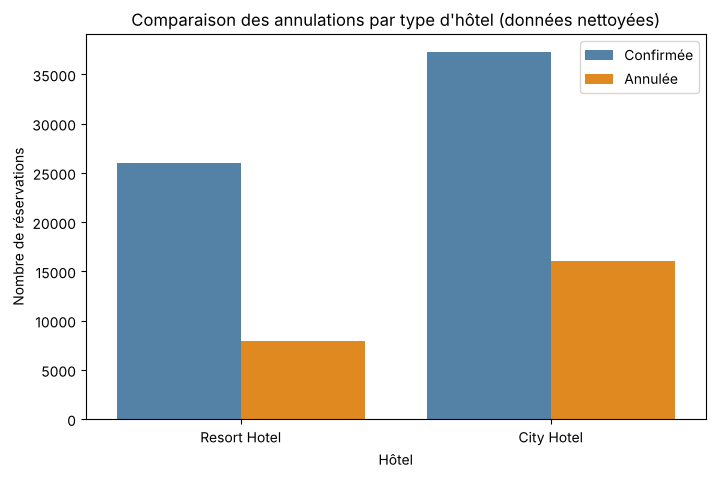

In [5]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="hotel", hue="is_canceled", palette=["steelblue", "darkorange"])
plt.title("Comparaison des annulations par type d'hôtel (données nettoyées)")
plt.xlabel("Hôtel")
plt.ylabel("Nombre de réservations")
plt.legend(["Confirmée", "Annulée"])
plt.show()

- Sur les données nettoyées, le City Hotel a plus de réservations et plus d'annulations que le Resort Hotel. Les taux exacts sont calculés en SQL (requête 2.1).

# 2. SQL / Analyse de l’activité

## 1. Chargement des données SQL

In [6]:
import sqlite3

conn = sqlite3.connect("hotel_bookings.db")
df.to_sql("bookings", conn, if_exists="replace", index=False)

87208

- Les 87 208 réservations nettoyées sont chargées dans la table bookings (SQLite), le même nombre que le CSV nettoyé.

## 2. requêtes SQL métier (SQLite)

## 2.1 Taux d'annulation global par type d'hôtel

In [7]:
q1 = """
    SELECT hotel, COUNT(*) as total_reservations, 
           SUM(is_canceled) as total_canceled,
           ROUND(AVG(is_canceled) * 100, 2) as cancellation_rate_pct
    FROM bookings GROUP BY hotel;
"""
display(pd.read_sql(q1, conn))

,hotel,total_reservations,total_canceled,cancellation_rate_pct
0,City Hotel,53267,16030,30.09
1,Resort Hotel,33941,7961,23.46


- City Hotel : 53 267 réservations, 16 030 annulées, soit 30,09 %.
- Resort Hotel : 33 941 réservations, 7 961 annulées, soit 23,46 %.
- Pour la direction : le City Hotel est le plus exposé, en volume comme en taux.

## 2.2 Taux d'annulation par type de client

In [8]:
q2 = """
    SELECT customer_type, COUNT(*) as total, 
           ROUND(AVG(is_canceled) * 100, 2) as cancellation_rate_pct
    FROM bookings GROUP BY customer_type ORDER BY cancellation_rate_pct DESC;
"""
display(pd.read_sql(q2, conn))

,customer_type,total,cancellation_rate_pct
0,Transient,71859,30.14
1,Contract,3134,16.31
2,Transient-Party,11686,15.22
3,Group,529,7.75


- Les clients Transient (réservation individuelle) sont les plus nombreux (71 859) et annulent le plus : 30,14 %.
- Contract 16,31 %, Transient-Party 15,22 %, Group 7,75 %.
- Pour la direction : l'effort de prévention doit d'abord viser les réservations individuelles.

## 2.3 Impact du délai de réservation (lead_time) moyen sur l'annulation

In [9]:
q3 = """
    SELECT is_canceled, ROUND(AVG(lead_time), 1) as avg_lead_time
    FROM bookings GROUP BY is_canceled;
"""
display(pd.read_sql(q3, conn))

,is_canceled,avg_lead_time
0,0,70.2
1,1,105.6


- Les réservations annulées ont été faites en moyenne 105,6 jours avant l'arrivée, contre 70,2 jours pour les réservations honorées.
- Pour la direction : plus une réservation est faite tôt, plus elle doit être surveillée.

## 2.4 Top 5 des pays d'origine avec le plus de réservations et leurs annulations

In [10]:
q4 = """
    SELECT country, COUNT(*) as total, 
           ROUND(AVG(is_canceled) * 100, 2) as cancellation_rate_pct
    FROM bookings GROUP BY country HAVING total > 1000 
    ORDER BY total DESC LIMIT 5;
"""
display(pd.read_sql(q4, conn))

,country,total,cancellation_rate_pct
0,PRT,27335,35.72
1,GBR,10422,19.04
2,FRA,8823,19.63
3,ESP,7244,25.70
4,DEU,5385,19.55


- Le Portugal (PRT) domine avec 27 335 réservations et le taux d'annulation le plus élevé du top 5 : 35,72 %.
- Les autres pays du top 5 sont entre 19,04 % (GBR) et 25,70 % (ESP).
- À interpréter avec prudence : country n'est pas utilisée dans le modèle, car le pays peut être complété ou corrigé à l'arrivée du client.

## 2.5 Impact des demandes spéciales sur le taux d'annulation

In [11]:
q5 = """
    SELECT total_of_special_requests, COUNT(*) as total,
           ROUND(AVG(is_canceled) * 100, 2) as cancellation_rate_pct
    FROM bookings GROUP BY total_of_special_requests ORDER BY total_of_special_requests;
"""
display(pd.read_sql(q5, conn))

,total_of_special_requests,total,cancellation_rate_pct
0,0,43774,33.23
1,1,28971,22.43
2,2,11793,21.32
3,3,2314,17.11
4,4,320,10.63
5,5,36,5.56


- Sans demande spéciale (43 774 réservations), le taux d'annulation est de 33,23 %. Il baisse avec le nombre de demandes, jusqu'à 5,56 % pour 5 demandes (36 réservations seulement).
- Un client qui fait des demandes semble plus engagé. Mais les demandes peuvent être ajoutées après la réservation : la variable n'est donc pas utilisée dans le modèle.

## 2.6 CTE avancée : Classement des mois par volume et taux d'annulation

In [12]:
q6 = """
    WITH MonthlyStats AS (
        SELECT arrival_date_month, COUNT(*) as total,
               SUM(is_canceled) as canceled
        FROM bookings GROUP BY arrival_date_month
    )
    SELECT arrival_date_month, total, 
           ROUND((CAST(canceled AS FLOAT) / total) * 100, 2) as cancel_rate
    FROM MonthlyStats ORDER BY total DESC;
"""
display(pd.read_sql(q6, conn))

,arrival_date_month,total,cancel_rate
0,August,11238,32.19
1,July,10041,31.82
2,May,8344,29.27
3,April,7900,30.46
4,June,7756,30.34
5,March,7487,24.42
6,October,6916,23.68
7,September,6674,24.47
8,February,6083,23.21
9,December,5112,26.94


- Août (11 238 réservations, 32,19 %) et juillet (10 041, 31,82 %) sont les mois les plus chargés et parmi les plus annulés.
- Les taux les plus bas sont en novembre (21,15 %) et janvier (22,14 %).
- Pour la direction : les mois d'été demandent le plus de vigilance sur les annulations.

# 3. Machine Learning / Classification

## 3.1 Sélection des variables et prétraitement (Pipeline)

**Moment de la prédiction** : au moment où la réservation est enregistrée. Le modèle n'utilise donc que des informations connues à cet instant.

Variables exclues et pourquoi :
- reservation_status et reservation_status_date : elles contiennent l'issue de la réservation (fuite de données).
- assigned_room_type, booking_changes, days_in_waiting_list, required_car_parking_spaces, total_of_special_requests : elles peuvent changer ou n'être connues qu'après la réservation, voire à l'arrivée.
- country : peut être complété à l'arrivée du client.
- agent et company : ce sont des identifiants, pas des quantités.
- arrival_date_year, week_number et day_of_month : on garde seulement le mois, pour ne pas apprendre des dates précises du passé.

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42

# Variables connues au moment de la réservation uniquement
num_cols = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "adr",
]
cat_cols = [
    "hotel",
    "arrival_date_month",
    "meal",
    "market_segment",
    "distribution_channel",
    "reserved_room_type",
    "deposit_type",
    "customer_type",
]
features = num_cols + cat_cols
X = df[features]
y = df["is_canceled"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ]
)

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)
print(X_train.shape, X_test.shape, round(y_train.mean() * 100, 2))

(69766, 18) (17442, 18) 27.51


- 69 766 réservations pour l'entraînement et 17 442 pour le test, avec 18 variables.
- stratify=y garde la même part d'annulations dans les deux jeux (27,51 % dans le train).
- L'encodage est appris sur le train seulement, puis appliqué au test.

## 3.2 Entraînement et comparaison des modèles

## Modèle 1 : Régression Logistique

In [14]:
lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr.fit(X_train_prep, y_train)
proba_lr = lr.predict_proba(X_test_prep)[:, 1]
print(f"ROC-AUC Logistic Regression: {roc_auc_score(y_test, proba_lr):.4f}")
print(classification_report(y_test, lr.predict(X_test_prep)))

ROC-AUC Logistic Regression: 0.7483
              precision    recall  f1-score   support

           0       0.76      0.96      0.85     12644
           1       0.68      0.20      0.31      4798

    accuracy                           0.75     17442
   macro avg       0.72      0.58      0.58     17442
weighted avg       0.74      0.75      0.70     17442



## Modèle 2 : Random Forest

In [15]:
rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=RANDOM_STATE)
rf.fit(X_train_prep, y_train)
proba_rf = rf.predict_proba(X_test_prep)[:, 1]
print(f"ROC-AUC Random Forest: {roc_auc_score(y_test, proba_rf):.4f}")
print(classification_report(y_test, rf.predict(X_test_prep)))

ROC-AUC Random Forest: 0.7761
              precision    recall  f1-score   support

           0       0.75      1.00      0.85     12644
           1       0.90      0.11      0.19      4798

    accuracy                           0.75     17442
   macro avg       0.82      0.55      0.52     17442
weighted avg       0.79      0.75      0.67     17442



## Modèle 3 : Arbre de décision

In [16]:
dt = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)
dt.fit(X_train_prep, y_train)
proba_dt = dt.predict_proba(X_test_prep)[:, 1]
print(f"ROC-AUC Decision Tree: {roc_auc_score(y_test, proba_dt):.4f}")
print(classification_report(y_test, dt.predict(X_test_prep)))

ROC-AUC Decision Tree: 0.7487
              precision    recall  f1-score   support

           0       0.74      1.00      0.85     12644
           1       0.98      0.08      0.15      4798

    accuracy                           0.75     17442
   macro avg       0.86      0.54      0.50     17442
weighted avg       0.81      0.75      0.66     17442



## 3.3 Comparaison des modèles en validation croisée

In [17]:
modeles = {
    "Référence (classe majoritaire)": DummyClassifier(),
    "Régression logistique": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Arbre de décision": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=RANDOM_STATE),
}
for nom, modele in modeles.items():
    scores = cross_val_score(make_pipeline(preprocessor, modele), X_train, y_train, cv=5, scoring="roc_auc")
    print(nom, round(scores.mean(), 4), round(scores.std(), 4))

Référence (classe majoritaire) 0.5 0.0


Régression logistique 0.7404 0.0041


Arbre de décision 0.7416 0.0055


Random Forest 0.7691 0.0047


| Modèle | AUC moyenne (validation croisée, 5 plis) | Écart-type |
|---|---|---|
| Référence (classe majoritaire) | 0,5 | 0,0 |
| Régression logistique | 0,7404 | 0,0041 |
| Arbre de décision | 0,7416 | 0,0055 |
| Random Forest | 0,7691 | 0,0047 |

- Les 3 modèles font nettement mieux que la référence (0,5 = hasard).
- Le Random Forest a la meilleure AUC moyenne, et les écarts-types sont faibles : le classement est stable d'un pli à l'autre.
- Sur le test, son AUC est de 0,7761, proche de la validation croisée : pas de surapprentissage marqué.
- **Modèle retenu : Random Forest.**

**Pourquoi l'AUC** : la direction veut classer les réservations de la plus risquée à la moins risquée pour en choisir 100. L'AUC mesure justement la capacité à bien classer. Au seuil par défaut de 0,5, le rappel des annulations est faible (0,11 pour le Random Forest, 0,20 pour la régression logistique, 0,08 pour l'arbre) : on n'utilise donc pas ce seuil, mais un classement par probabilité.

## 3.4 Erreurs du modèle retenu

In [18]:
print(confusion_matrix(y_test, rf.predict(X_test_prep)))

[[12588    56]
 [ 4282   516]]


- 516 annulations bien détectées.
- 4 282 annulations non détectées (faux négatifs) : la chambre risque de rester vide sans que l'hôtel ait été prévenu.
- 56 fausses alertes (faux positifs) : un client qui vient bien est considéré à risque. Si on le contacte trop, il peut être gêné.
- 12 588 réservations honorées bien reconnues.

Au seuil de 0,5, le modèle est très prudent : quand il annonce une annulation, il a souvent raison, mais il en rate beaucoup. C'est pourquoi la règle de priorisation utilise le classement par probabilité plutôt que ce seuil.

# 4. Décision / Recommandations

## 4.1 Règle de priorisation

In [19]:
# Simulation : 1 000 réservations à venir tirées au hasard dans le jeu de test
test = X_test.copy()
test["proba"] = rf.predict_proba(X_test_prep)[:, 1]
test["annule"] = y_test
lot = test.sample(1000, random_state=RANDOM_STATE)

# Priorisation des 100 réservations avec la plus forte probabilité d'annulation
top100 = lot.nlargest(100, "proba")
print(top100["annule"].sum(), round(lot["annule"].mean() * 100, 1))
print(top100["deposit_type"].value_counts())

75 30.3
deposit_type
No Deposit    82
Non Refund    18
Name: count, dtype: int64


- Sur 1 000 réservations tirées au hasard dans le test, le taux d'annulation moyen est de 30,3 %.
- Parmi les 100 réservations les plus risquées selon le modèle, 75 ont réellement été annulées.
- 18 de ces 100 réservations ont un acompte non remboursable (Non Refund). Pour celles-là, l'hôtel garde l'argent en cas d'annulation : les appeler a peu d'intérêt. On teste donc une variante sans elles.

In [20]:
# Variante : on écarte les réservations avec acompte non remboursable (l'hôtel garde déjà l'argent)
top100_sans_acompte = lot[lot["deposit_type"] != "Non Refund"].nlargest(100, "proba")
print(top100_sans_acompte["annule"].sum())

69


## Synthèse et recommandations métier

1. **Règle d'action** : chaque semaine, classer les réservations à venir par probabilité d'annulation (Random Forest), écarter celles avec acompte non remboursable, puis contacter les 100 premières sur 1 000 pour reconfirmer le séjour ou proposer une option de flexibilité.
2. **Justification** : dans la simulation, cette règle cible 69 annulations réelles sur 100 réservations contactées, alors que le taux d'annulation moyen des 1 000 réservations est de 30,3 %. Sans écarter les Non Refund, on cible 75 annulations sur 100, mais 18 de ces réservations ne coûtent rien à l'hôtel si elles sont annulées.
3. **Limites** :
   - données de 2015 à 2017 et deux hôtels seulement : les comportements ont pu changer ;
   - simulation faite sur un seul tirage de 1 000 réservations du jeu de test ;
   - au seuil de 0,5, le modèle rate 4 282 annulations sur le test : il sert à prioriser, pas à prévoir toutes les annulations ;
   - le coût d'un appel et son effet réel ne sont pas connus, et contacter un client peut parfois provoquer l'annulation ;
   - les réglages des modèles (max_depth) n'ont pas été optimisés.